<center><h1>Liu_Chun-Fu_HW7</h1></center>

Name: Chun-Fu Liu
<br>
Github Username: Albert927
<br>
USC ID: 5635413630

## 1. Multi-class and Multi-Label Classification Using Support Vector Machines

Import packages

In [28]:
from pathlib import Path
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.model_selection import train_test_split

RANDOM_STATE = 42

from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.multiclass import OneVsRestClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.svm import LinearSVC

from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

from sklearn.cluster import KMeans
from sklearn.metrics import calinski_harabasz_score

In [29]:
def evaluate_predictions(y_true, y_pred):
    true_values = np.asarray(y_true)
    pred_values = np.asarray(y_pred)

    matches = true_values == pred_values

    return pd.Series({
        "Exact Match": matches.all(axis=1).mean(),
        "Hamming Score": matches.mean(),
        "Hamming Loss": (~matches).mean(),
        "Average Hamming Distance": (~matches).sum(axis=1).mean()
    })

### (a) Download the Anuran Calls (MFCCs) Data Set

In [30]:
data_path = Path(r"C:\Users\liual\Desktop\DSCI 552\HW\hw7\Anuran Calls (MFCCs)\Frogs_MFCCs.csv")
df = pd.read_csv(data_path)
print(f"Data shape: {df.shape}")
print(f"missing values: {df.isna().sum().sum()}")

df.head(3)

Data shape: (7195, 26)
missing values: 0


,MFCCs_ 1,MFCCs_ 2,MFCCs_ 3,MFCCs_ 4,MFCCs_ 5,MFCCs_ 6,MFCCs_ 7,MFCCs_ 8,MFCCs_ 9,MFCCs_10,...,MFCCs_17,MFCCs_18,MFCCs_19,MFCCs_20,MFCCs_21,MFCCs_22,Family,Genus,Species,RecordID
0,1.0,0.152936,-0.105586,0.200722,0.317201,0.260764,0.100945,-0.150063,-0.171128,0.124676,...,-0.108351,-0.077623,-0.009568,0.057684,0.118680,0.014038,Leptodactylidae,Adenomera,AdenomeraAndre,1
1,1.0,0.171534,-0.098975,0.268425,0.338672,0.268353,0.060835,-0.222475,-0.207693,0.170883,...,-0.090974,-0.056510,-0.035303,0.020140,0.082263,0.029056,Leptodactylidae,Adenomera,AdenomeraAndre,1
2,1.0,0.152317,-0.082973,0.287128,0.276014,0.189867,0.008714,-0.242234,-0.219153,0.232538,...,-0.050691,-0.023590,-0.066722,-0.025083,0.099108,0.077162,Leptodactylidae,Adenomera,AdenomeraAndre,1


In [31]:
feature_columns = [
    column for column in df.columns
    if column.startswith("MFCCs_")
]

label_columns = ["Family", "Genus", "Species"]

X = df[feature_columns].copy()
y = df[label_columns].copy()

print("Feature matrix shape:", X.shape)
print("Target matrix shape:", y.shape)

for label in label_columns:
    print(f"\nClass counts for {label}:")
    print(y[label].value_counts())

Feature matrix shape: (7195, 22)
Target matrix shape: (7195, 3)

Class counts for Family:
Family
Leptodactylidae    4420
Hylidae            2165
Dendrobatidae       542
Bufonidae            68
Name: count, dtype: int64

Class counts for Genus:
Genus
Adenomera        4150
Hypsiboas        1593
Ameerega          542
Dendropsophus     310
Leptodactylus     270
Scinax            148
Osteocephalus     114
Rhinella           68
Name: count, dtype: int64

Class counts for Species:
Species
AdenomeraHylaedactylus    3478
HypsiboasCordobae         1121
AdenomeraAndre             672
Ameeregatrivittata         542
HypsiboasCinerascens       472
HylaMinuta                 310
LeptodactylusFuscus        270
ScinaxRuber                148
OsteocephalusOophagus      114
Rhinellagranulosa           68
Name: count, dtype: int64


In [32]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=RANDOM_STATE
)

print("Training features shape:", X_train.shape)
print("Test features shape:", X_test.shape)
print("Training targets shape:", y_train.shape)
print("Test targets shape:", y_test.shape)

Training features shape: (5036, 22)
Test features shape: (2159, 22)
Training targets shape: (5036, 3)
Test targets shape: (2159, 3)


### (b) Train a classifier for each label

#### (i) Research

Exact match (subset accuracy) is the proportion of samples for which all three predicted labels—Family, Genus, and Species—are correct. A sample receives credit only when its entire predicted label triplet matches the true triplet.

Hamming loss is the number of incorrect label predictions divided by the total number of label predictions. With N samples and three output labels, the denominator is 3N. Lower values indicate better performance.

In this notebook, Hamming score is defined as one minus Hamming loss, representing the proportion of correctly predicted output labels. This is a label-wise accuracy definition, rather than a Jaccard-based set similarity.

Average Hamming distance is the average number of incorrectly predicted output labels per sample. For this dataset, it equals three times the Hamming loss.

Exact match and Hamming score are better when higher, whereas Hamming loss and average Hamming distance are better when lower.

References:
- https://scikit-learn.org/stable/modules/generated/sklearn.metrics.accuracy_score.html
- https://scikit-learn.org/stable/modules/model_evaluation.html#hamming-loss

#### (ii) Train a SVM for each of the labels

In [33]:
# Define candidate hyperparameters.
rbf_param_grid = {
    "svm__estimator__C": [0.1, 1, 10, 100],
    "svm__estimator__gamma": [0.01, 0.1, 1]
}

cv = StratifiedKFold(
    n_splits=10,
    shuffle=True,
    random_state=RANDOM_STATE
)

rbf_models = {}
rbf_cv_rows = []

for label in label_columns:
    print(f"\nTraining RBF SVM for {label}...", flush=True)

    pipeline = Pipeline([
        ("scaler", StandardScaler()),
        ("svm", OneVsRestClassifier(SVC(kernel="rbf")))
    ])

    search = GridSearchCV(
        estimator=pipeline,
        param_grid=rbf_param_grid,
        scoring="accuracy",
        cv=cv,
        n_jobs=-1,
        refit=True,
        verbose=1
    )

    search.fit(X_train, y_train[label])

    rbf_models[label] = search.best_estimator_

    best_c = search.best_params_["svm__estimator__C"]
    best_gamma = search.best_params_["svm__estimator__gamma"]

    rbf_cv_rows.append({
        "Label": label,
        "Best C": best_c,
        "Best gamma": best_gamma,
        "Equivalent sigma": np.sqrt(1 / (2 * best_gamma)),
        "Best CV Accuracy": search.best_score_
    })

    print("Best parameters:", search.best_params_)
    print(f"Best CV accuracy: {search.best_score_:.4f}")

rbf_cv_results = pd.DataFrame(rbf_cv_rows)

display(rbf_cv_results)


Training RBF SVM for Family...
Fitting 10 folds for each of 12 candidates, totalling 120 fits
Best parameters: {'svm__estimator__C': 10, 'svm__estimator__gamma': 0.1}
Best CV accuracy: 0.9905

Training RBF SVM for Genus...
Fitting 10 folds for each of 12 candidates, totalling 120 fits
Best parameters: {'svm__estimator__C': 10, 'svm__estimator__gamma': 0.1}
Best CV accuracy: 0.9891

Training RBF SVM for Species...
Fitting 10 folds for each of 12 candidates, totalling 120 fits
Best parameters: {'svm__estimator__C': 10, 'svm__estimator__gamma': 0.1}
Best CV accuracy: 0.9889


,Label,Best C,Best gamma,Equivalent sigma,Best CV Accuracy
0,Family,10,0.1,2.236068,0.990468
1,Genus,10,0.1,2.236068,0.989078
2,Species,10,0.1,2.236068,0.988880


In [34]:
# Predict each target using its fitted pipeline.
rbf_predictions = pd.DataFrame(
    {
        label: rbf_models[label].predict(X_test)
        for label in label_columns
    },
    index=X_test.index
)

# Keep the target columns in the same order.
rbf_predictions = rbf_predictions[label_columns]

# Calculate test accuracy separately for each target.
rbf_test_accuracy = pd.DataFrame({
    "Label": label_columns,
    "Test Accuracy": [
        (y_test[label] == rbf_predictions[label]).mean()
        for label in label_columns
    ]
})

print("Test accuracy by target:")
display(rbf_test_accuracy)

# Evaluate all three targets together.
rbf_test_metrics = evaluate_predictions(
    y_test[label_columns],
    rbf_predictions
)

print("\nOverall multi-output test metrics:")
display(rbf_test_metrics.to_frame(name="RBF SVM"))

Test accuracy by target:


,Label,Test Accuracy
0,Family,0.993516
1,Genus,0.988421
2,Species,0.987957



Overall multi-output test metrics:


,RBF SVM
Exact Match,0.986568
Hamming Score,0.989964
Hamming Loss,0.010036
Average Hamming Distance,0.030107


Separate RBF SVM classifiers were trained for Family, Genus, and Species using a one-vs-rest strategy. Standardization was performed within each cross-validation fold using a pipeline. Ten-fold cross-validation selected C = 10 and gamma = 0.1 for all three targets, corresponding to a Gaussian kernel width of approximately 2.2361.

Test accuracies were 0.993516 for Family, 0.988421 for Genus, and 0.987957 for Species. The exact match accuracy was 0.986568, meaning that approximately 98.66% of test samples had all three labels predicted correctly.

Using label-wise accuracy as the definition of Hamming score, the Hamming score was 0.989964, the Hamming loss was 0.010036, and the average Hamming distance was 0.030107. Test accuracies were close to the cross-validation accuracies. However, these aggregate metrics alone do not establish strong performance for every minority class.

#### (iii) Repeat 1(b)ii with L1-penalized SVMs

In [35]:
l1_param_grid = {
    "svm__C": [0.001, 0.01, 0.1, 1, 10, 100, 1000]
}

l1_models = {}
l1_cv_rows = []

for label in label_columns:
    print(f"\nTraining L1 SVM for {label}...", flush=True)

    pipeline = Pipeline([
        ("scaler", StandardScaler()),
        ("svm", LinearSVC(
            penalty="l1",
            loss="squared_hinge",
            dual=False,
            multi_class="ovr",
            max_iter=100000,
            random_state=RANDOM_STATE
        ))
    ])

    search = GridSearchCV(
        estimator=pipeline,
        param_grid=l1_param_grid,
        scoring="accuracy",
        cv=cv,
        n_jobs=-1,
        refit=True,
        verbose=1
    )

    search.fit(X_train, y_train[label])

    l1_models[label] = search.best_estimator_

    l1_cv_rows.append({
        "Label": label,
        "Best C": search.best_params_["svm__C"],
        "Best CV Accuracy": search.best_score_
    })

    print("Best parameters:", search.best_params_)
    print(f"Best CV accuracy: {search.best_score_:.4f}")

l1_cv_results = pd.DataFrame(l1_cv_rows)

display(l1_cv_results)


Training L1 SVM for Family...
Fitting 10 folds for each of 7 candidates, totalling 70 fits
Best parameters: {'svm__C': 10}
Best CV accuracy: 0.9412

Training L1 SVM for Genus...
Fitting 10 folds for each of 7 candidates, totalling 70 fits
Best parameters: {'svm__C': 1000}
Best CV accuracy: 0.9517

Training L1 SVM for Species...
Fitting 10 folds for each of 7 candidates, totalling 70 fits
Best parameters: {'svm__C': 10}
Best CV accuracy: 0.9607


,Label,Best C,Best CV Accuracy
0,Family,10,0.941223
1,Genus,1000,0.951750
2,Species,10,0.960682


In [36]:
# Predict each target using its fitted L1 SVM pipeline.
l1_predictions = pd.DataFrame(
    {
        label: l1_models[label].predict(X_test)
        for label in label_columns
    },
    index=X_test.index
)

l1_predictions = l1_predictions[label_columns]

# Calculate test accuracy for each target.
l1_test_accuracy = pd.DataFrame({
    "Label": label_columns,
    "Test Accuracy": [
        (y_test[label] == l1_predictions[label]).mean()
        for label in label_columns
    ]
})

print("L1 SVM test accuracy by target:")
display(l1_test_accuracy)

# Evaluate all three targets together.
l1_test_metrics = evaluate_predictions(
    y_test[label_columns],
    l1_predictions
)

print("\nL1 SVM overall multi-output test metrics:")
display(l1_test_metrics.to_frame(name="L1 SVM"))

# Compare the two models.
model_comparison = pd.concat(
    [
        rbf_test_metrics.rename("RBF SVM"),
        l1_test_metrics.rename("L1 SVM")
    ],
    axis=1
)

print("\nTest performance comparison:")
display(model_comparison)

L1 SVM test accuracy by target:


,Label,Test Accuracy
0,Family,0.928208
1,Genus,0.941640
2,Species,0.959240



L1 SVM overall multi-output test metrics:


,L1 SVM
Exact Match,0.912459
Hamming Score,0.943029
Hamming Loss,0.056971
Average Hamming Distance,0.170912



Test performance comparison:


,RBF SVM,L1 SVM
Exact Match,0.986568,0.912459
Hamming Score,0.989964,0.943029
Hamming Loss,0.010036,0.056971
Average Hamming Distance,0.030107,0.170912


Standardized L1-penalized linear SVMs were trained separately for Family, Genus, and Species. Ten-fold cross-validation selected C = 10, 1000, and 10, respectively.

Test accuracies were 0.928208 for Family, 0.941640 for Genus, and 0.959240 for Species. Exact match accuracy was 0.912459, Hamming score was 0.943029, Hamming loss was 0.056971, and average Hamming distance was 0.170912.

The RBF SVM performed better on all four overall test metrics. This is consistent with nonlinear decision boundaries being useful for this dataset, although the comparison changes both the kernel and the regularization method.

#### (iv) Repeat 1(b)iii by using SMOTE or any other method for imbalance

In [37]:
smote_param_grid = {
    "svm__C": [0.001, 0.01, 0.1, 1, 10, 100, 1000]
}

smote_models = {}
smote_cv_rows = []

for label in label_columns:
    print(f"\nTraining L1 SVM with SMOTE for {label}...", flush=True)

    pipeline = ImbPipeline([
        ("scaler", StandardScaler()),
        ("smote", SMOTE(
            sampling_strategy="auto",
            k_neighbors=5,
            random_state=RANDOM_STATE
        )),
        ("svm", LinearSVC(
            penalty="l1",
            loss="squared_hinge",
            dual=False,
            multi_class="ovr",
            max_iter=100000,
            random_state=RANDOM_STATE
        ))
    ])

    search = GridSearchCV(
        estimator=pipeline,
        param_grid=smote_param_grid,
        scoring="accuracy",
        cv=cv,
        n_jobs=-1,
        refit=True,
        verbose=1
    )

    search.fit(X_train, y_train[label])

    smote_models[label] = search.best_estimator_

    smote_cv_rows.append({
        "Label": label,
        "Best C": search.best_params_["svm__C"],
        "Best CV Accuracy": search.best_score_
    })

    print("Best parameters:", search.best_params_)
    print(f"Best CV accuracy: {search.best_score_:.4f}")

smote_cv_results = pd.DataFrame(smote_cv_rows)

display(smote_cv_results)


Training L1 SVM with SMOTE for Family...
Fitting 10 folds for each of 7 candidates, totalling 70 fits
Best parameters: {'svm__C': 10}
Best CV accuracy: 0.9232

Training L1 SVM with SMOTE for Genus...
Fitting 10 folds for each of 7 candidates, totalling 70 fits
Best parameters: {'svm__C': 1}
Best CV accuracy: 0.9128

Training L1 SVM with SMOTE for Species...
Fitting 10 folds for each of 7 candidates, totalling 70 fits
Best parameters: {'svm__C': 10}
Best CV accuracy: 0.9581


,Label,Best C,Best CV Accuracy
0,Family,10,0.923156
1,Genus,1,0.912837
2,Species,10,0.958103


In [38]:
# Predict the original, unchanged test set.
smote_predictions = pd.DataFrame(
    {
        label: smote_models[label].predict(X_test)
        for label in label_columns
    },
    index=X_test.index
)

smote_predictions = smote_predictions[label_columns]

# Calculate test accuracy for each target.
smote_test_accuracy = pd.DataFrame({
    "Label": label_columns,
    "Test Accuracy": [
        (y_test[label] == smote_predictions[label]).mean()
        for label in label_columns
    ]
})

print("L1 SVM + SMOTE test accuracy by target:")
display(smote_test_accuracy)

# Calculate overall metrics.
smote_test_metrics = evaluate_predictions(
    y_test[label_columns],
    smote_predictions
)

# Compare all three models.
model_comparison = pd.concat(
    [
        rbf_test_metrics.rename("RBF SVM"),
        l1_test_metrics.rename("L1 SVM"),
        smote_test_metrics.rename("L1 SVM + SMOTE")
    ],
    axis=1
)

print("\nOverall test performance comparison:")
display(model_comparison)

L1 SVM + SMOTE test accuracy by target:


,Label,Test Accuracy
0,Family,0.909217
1,Genus,0.902270
2,Species,0.957851



Overall test performance comparison:


,RBF SVM,L1 SVM,L1 SVM + SMOTE
Exact Match,0.986568,0.912459,0.853636
Hamming Score,0.989964,0.943029,0.923113
Hamming Loss,0.010036,0.056971,0.076887
Average Hamming Distance,0.030107,0.170912,0.230662


In [39]:
recall_rows = []

for label in label_columns:
    for class_name in sorted(y_test[label].unique()):
        mask = y_test[label] == class_name

        l1_recall = (
            l1_predictions.loc[mask, label] == class_name
        ).mean()

        smote_recall = (
            smote_predictions.loc[mask, label] == class_name
        ).mean()

        recall_rows.append({
            "Target": label,
            "Class": class_name,
            "Test Support": int(mask.sum()),
            "L1 Recall": l1_recall,
            "SMOTE Recall": smote_recall,
            "Recall Change": smote_recall - l1_recall
        })

recall_comparison = pd.DataFrame(recall_rows)

print("Per-class recall comparison:")
with pd.option_context("display.max_rows", None):
    display(recall_comparison)

# Average recall across classes, giving each class equal weight.
balanced_accuracy_comparison = (
    recall_comparison
    .groupby("Target")[["L1 Recall", "SMOTE Recall"]]
    .mean()
    .rename(columns={
        "L1 Recall": "L1 Balanced Accuracy",
        "SMOTE Recall": "SMOTE Balanced Accuracy"
    })
)

print("\nBalanced accuracy comparison:")
display(balanced_accuracy_comparison)

Per-class recall comparison:


,Target,Class,Test Support,L1 Recall,SMOTE Recall,Recall Change
0,Family,Bufonidae,27,0.000000,0.888889,0.888889
1,Family,Dendrobatidae,162,0.895062,0.975309,0.080247
2,Family,Hylidae,623,0.903692,0.866774,-0.036918
3,Family,Leptodactylidae,1347,0.962138,0.921307,-0.040831
4,Genus,Adenomera,1251,0.978417,0.890488,-0.087930
5,Genus,Ameerega,162,0.932099,0.956790,0.024691
6,Genus,Dendropsophus,84,0.714286,0.892857,0.178571
7,Genus,Hypsiboas,468,0.970085,0.912393,-0.057692
8,Genus,Leptodactylus,96,0.906250,0.895833,-0.010417
9,Genus,Osteocephalus,34,0.500000,0.882353,0.382353



Balanced accuracy comparison:


,L1 Balanced Accuracy,SMOTE Balanced Accuracy
Target,,
Family,0.690223,0.913069
Genus,0.769036,0.916202
Species,0.894759,0.927814


SMOTE was applied separately for each target within the training folds, after standardization. Validation and test data were not resampled. Ten-fold cross-validation selected C = 10 for Family, C = 1 for Genus, and C = 10 for Species.

Compared with the original L1 SVM, SMOTE reduced exact match accuracy from 0.912459 to 0.853636 and increased Hamming loss from 0.056971 to 0.076887. However, balanced accuracy improved from 0.690223 to 0.913069 for Family, from 0.769036 to 0.916202 for Genus, and from 0.894759 to 0.927814 for Species.

Several minority classes showed substantial recall improvements. For example, Bufonidae recall increased from 0 to 0.888889, and Rhinella recall increased from 0.259259 to 0.925926. Some common classes experienced lower recall, contributing to the decline in overall accuracy.

Among the three models, the RBF SVM achieved the best exact match and Hamming metrics. Between the two L1 models, SMOTE improved class-balanced recall at the cost of overall accuracy. These results demonstrate a trade-off between aggregate correctness and minority-class detection.

## 2. K-Means Clustering on a Multi-Class and Multi-Label Data Set

### (a) Use k-means clustering

In [40]:
# Use all original MFCC features, without labels or RecordID.
X_cluster = X.to_numpy(copy=True)


def select_k_by_ch(features, seed, show_progress=False):
    score_rows = []
    best_score = -np.inf
    best_model = None

    for k in range(2, 51):
        model = KMeans(
            n_clusters=k,
            init="k-means++",
            n_init=10,
            random_state=seed
        )

        cluster_ids = model.fit_predict(features)
        score = calinski_harabasz_score(features, cluster_ids)

        score_rows.append({
            "k": k,
            "CH Score": score
        })

        if score > best_score:
            best_score = score
            best_model = model

        if show_progress and k % 10 == 0:
            print(f"Finished k = {k}", flush=True)

    return best_model, pd.DataFrame(score_rows)


# Run the first trial.
best_kmeans, ch_results = select_k_by_ch(
    X_cluster,
    seed=RANDOM_STATE,
    show_progress=True
)

print("\nSelected k:", best_kmeans.n_clusters)

print("\nTop 10 candidates by CH score:")
display(
    ch_results
    .sort_values("CH Score", ascending=False)
    .head(10)
)

Finished k = 10
Finished k = 20
Finished k = 30
Finished k = 40
Finished k = 50

Selected k: 2

Top 10 candidates by CH score:


,k,CH Score
0,2,3680.741349
1,3,3157.638923
2,4,2756.474989
3,5,2628.969989
4,6,2390.208399
5,7,2235.984884
6,8,2117.487050
7,9,2049.083055
8,10,1974.157009
9,11,1904.959459


### (b) Determine which family is the majority

In [41]:
# Attach cluster IDs to the true labels for interpretation.
clustered_labels = y[label_columns].copy()
clustered_labels["Cluster"] = best_kmeans.labels_

majority_rows = []

for cluster_id, group in clustered_labels.groupby("Cluster"):
    row = {
        "Cluster": cluster_id,
        "Cluster Size": len(group)
    }

    for label in label_columns:
        counts = group[label].value_counts()
        max_count = counts.max()

        # Break ties alphabetically for reproducibility.
        majority_label = sorted(
            counts[counts == max_count].index
        )[0]

        row[f"Majority {label}"] = majority_label
        row[f"{label} Majority Share"] = max_count / len(group)

    majority_rows.append(row)

cluster_majorities = pd.DataFrame(majority_rows)

display(cluster_majorities)

,Cluster,Cluster Size,Majority Family,Family Majority Share,Majority Genus,Genus Majority Share,Majority Species,Species Majority Share
0,0,3598,Leptodactylidae,0.965536,Adenomera,0.964425,AdenomeraHylaedactylus,0.964425
1,1,3597,Hylidae,0.567417,Hypsiboas,0.438977,HypsiboasCordobae,0.307756


### (c) Calculate the average Hamming distance, Hamming score, and Hamming loss

In [42]:
# Create a lookup table of representative labels for each cluster.
majority_lookup = (
    cluster_majorities
    .set_index("Cluster")[
        [f"Majority {label}" for label in label_columns]
    ]
    .copy()
)

majority_lookup.columns = label_columns

# Assign each sample its cluster's representative label triplet.
cluster_predictions = (
    majority_lookup.loc[best_kmeans.labels_, label_columns].copy()
)

# Restore the original sample index.
cluster_predictions.index = y.index

print("Labels assigned by clusters:")
display(cluster_predictions.head())

# Compare assigned labels with the true labels.
cluster_metrics = evaluate_predictions(
    y[label_columns],
    cluster_predictions
)

print("\nClustering evaluation for the first trial:")
display(cluster_metrics.to_frame(name="K-Means"))

Labels assigned by clusters:


,Family,Genus,Species
0,Hylidae,Hypsiboas,HypsiboasCordobae
1,Hylidae,Hypsiboas,HypsiboasCordobae
2,Hylidae,Hypsiboas,HypsiboasCordobae
3,Hylidae,Hypsiboas,HypsiboasCordobae
4,Hylidae,Hypsiboas,HypsiboasCordobae



Clustering evaluation for the first trial:


,K-Means
Exact Match,0.636136
Hamming Score,0.701459
Hamming Loss,0.298541
Average Hamming Distance,0.895622


In [43]:
def assign_cluster_majorities(cluster_ids, targets):
    assigned_labels = targets.copy()

    for cluster_id in np.unique(cluster_ids):
        mask = cluster_ids == cluster_id

        for label in targets.columns:
            # mode() returns tied modes in sorted order.
            majority_label = (
                targets.loc[mask, label]
                .mode()
                .iloc[0]
            )

            assigned_labels.loc[mask, label] = majority_label

    return assigned_labels

In [44]:
# Reuse the completed first trial.
monte_carlo_rows = [{
    "Trial": 1,
    "Seed": RANDOM_STATE,
    "Selected k": best_kmeans.n_clusters,
    **cluster_metrics.to_dict()
}]

for trial in range(1, 50):
    seed = RANDOM_STATE + trial

    print(
        f"Starting trial {trial + 1}/50, seed = {seed}...",
        flush=True
    )

    # Repeat the full search over candidate cluster counts.
    trial_model, _ = select_k_by_ch(
        X_cluster,
        seed=seed
    )

    # Determine representative labels separately in this trial.
    trial_predictions = assign_cluster_majorities(
        trial_model.labels_,
        y[label_columns]
    )

    trial_metrics = evaluate_predictions(
        y[label_columns],
        trial_predictions
    )

    monte_carlo_rows.append({
        "Trial": trial + 1,
        "Seed": seed,
        "Selected k": trial_model.n_clusters,
        **trial_metrics.to_dict()
    })

    print(
        f"Completed: k = {trial_model.n_clusters}, "
        f"average Hamming distance = "
        f"{trial_metrics['Average Hamming Distance']:.6f}",
        flush=True
    )

monte_carlo_results = pd.DataFrame(monte_carlo_rows)

print("\nNumber of completed trials:", len(monte_carlo_results))
display(monte_carlo_results.head())

Starting trial 2/50, seed = 43...
Completed: k = 2, average Hamming distance = 0.895622
Starting trial 3/50, seed = 44...
Completed: k = 2, average Hamming distance = 0.895622
Starting trial 4/50, seed = 45...
Completed: k = 2, average Hamming distance = 0.895622
Starting trial 5/50, seed = 46...
Completed: k = 2, average Hamming distance = 0.895622
Starting trial 6/50, seed = 47...
Completed: k = 2, average Hamming distance = 0.895622
Starting trial 7/50, seed = 48...
Completed: k = 2, average Hamming distance = 0.895622
Starting trial 8/50, seed = 49...
Completed: k = 2, average Hamming distance = 0.895622
Starting trial 9/50, seed = 50...
Completed: k = 2, average Hamming distance = 0.895622
Starting trial 10/50, seed = 51...
Completed: k = 2, average Hamming distance = 0.895622
Starting trial 11/50, seed = 52...
Completed: k = 2, average Hamming distance = 0.895622
Starting trial 12/50, seed = 53...
Completed: k = 2, average Hamming distance = 0.895622
Starting trial 13/50, seed = 

,Trial,Seed,Selected k,Exact Match,Hamming Score,Hamming Loss,Average Hamming Distance
0,1,42,2,0.636136,0.701459,0.298541,0.895622
1,2,43,2,0.636136,0.701459,0.298541,0.895622
2,3,44,2,0.636136,0.701459,0.298541,0.895622
3,4,45,2,0.636136,0.701459,0.298541,0.895622
4,5,46,2,0.636136,0.701459,0.298541,0.895622


In [45]:
metric_columns = [
    "Average Hamming Distance",
    "Hamming Score",
    "Hamming Loss",
    "Exact Match"
]

monte_carlo_summary = pd.DataFrame({
    "Mean": monte_carlo_results[metric_columns].mean(),
    "Standard Deviation": (
        monte_carlo_results[metric_columns].std(ddof=1)
    )
})

print("Summary across 50 trials:")
display(monte_carlo_summary)

print("\nSelected k frequencies:")
display(
    monte_carlo_results["Selected k"]
    .value_counts()
    .sort_index()
    .rename_axis("k")
    .to_frame(name="Number of Trials")
)

Summary across 50 trials:


,Mean,Standard Deviation
Average Hamming Distance,0.895622,1.121495e-16
Hamming Score,0.701459,1.121495e-16
Hamming Loss,0.298541,5.607473e-17
Exact Match,0.636136,1.121495e-16



Selected k frequencies:


,Number of Trials
k,
2,50


K-means clustering was performed on all 7,195 observations using the 22 original normalized MFCC features. No train/test split or SMOTE was used.

For each of 50 trials, k was selected by maximizing the Calinski–Harabasz (CH) index over k = 2, ..., 50. The CH index is undefined for k = 1. Each candidate used 10 initializations, and different random seeds were used across trials. True labels were used only after clustering to determine each cluster's majority Family, Genus, and Species.

All 50 trials selected k = 2. The mean average Hamming distance was 0.895622, with a sample standard deviation of approximately zero. The mean Hamming score was 0.701459, mean Hamming loss was 0.298541, and mean exact match accuracy was 0.636136. Standard deviations on the order of 10^-16 reflect floating-point roundoff.

The evaluation metrics were stable across trials. However, the selected two-cluster structure did not closely reproduce all biological categories: in the first trial, one cluster was dominated by AdenomeraHylaedactylus, while the other contained a mixture of species.

## 3. ISLR 12.6.2

In [46]:
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage, dendrogram
from scipy.spatial.distance import squareform

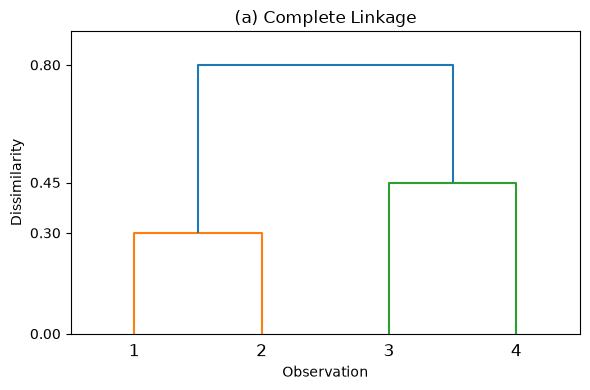

In [47]:
distance_matrix = np.array([
    [0.00, 0.30, 0.40, 0.70],
    [0.30, 0.00, 0.50, 0.80],
    [0.40, 0.50, 0.00, 0.45],
    [0.70, 0.80, 0.45, 0.00]
])

# Convert the distance matrix to condensed pairwise distances.
condensed_distances = squareform(distance_matrix)

complete_linkage = linkage(
    condensed_distances,
    method="complete"
)

fig, ax = plt.subplots(figsize=(6, 4))

dendrogram(
    complete_linkage,
    labels=["1", "2", "3", "4"],
    ax=ax
)

ax.set_title("(a) Complete Linkage")
ax.set_xlabel("Observation")
ax.set_ylabel("Dissimilarity")
ax.set_yticks([0, 0.30, 0.45, 0.80])
ax.set_ylim(0, 0.90)

plt.tight_layout()
plt.show()

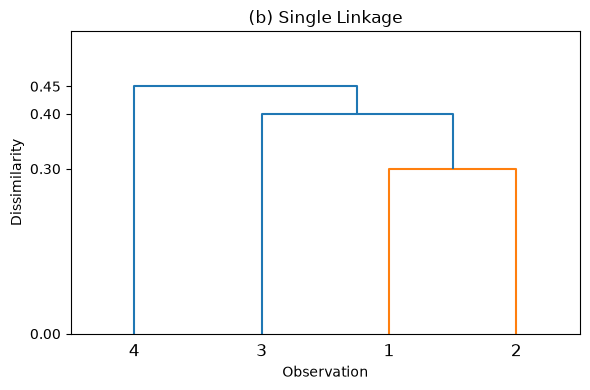

In [48]:
single_linkage = linkage(
    condensed_distances,
    method="single"
)

fig, ax = plt.subplots(figsize=(6, 4))

dendrogram(
    single_linkage,
    labels=["1", "2", "3", "4"],
    ax=ax
)

ax.set_title("(b) Single Linkage")
ax.set_xlabel("Observation")
ax.set_ylabel("Dissimilarity")
ax.set_yticks([0, 0.30, 0.40, 0.45])
ax.set_ylim(0, 0.55)

plt.tight_layout()
plt.show()

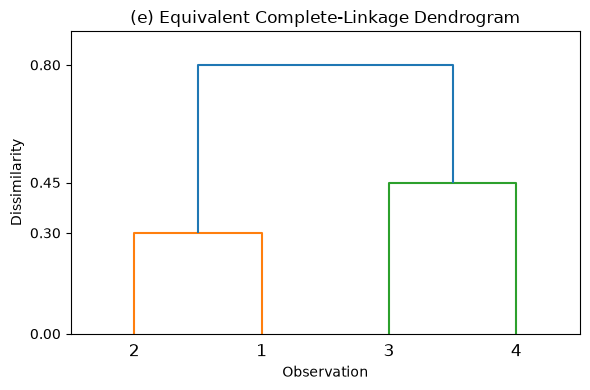

In [49]:
# Copy the complete-linkage result.
equivalent_linkage = complete_linkage.copy()

# Swap the children of the first merge: observations 1 and 2.
equivalent_linkage[0, [0, 1]] = (
    equivalent_linkage[0, [1, 0]]
)

fig, ax = plt.subplots(figsize=(6, 4))

dendrogram(
    equivalent_linkage,
    labels=["1", "2", "3", "4"],
    ax=ax
)

ax.set_title("(e) Equivalent Complete-Linkage Dendrogram")
ax.set_xlabel("Observation")
ax.set_ylabel("Dissimilarity")
ax.set_yticks([0, 0.30, 0.45, 0.80])
ax.set_ylim(0, 0.90)

plt.tight_layout()
plt.show()

**(a) Complete linkage**

Observations 1 and 2 merge at height 0.30. Observations 3 and 4 merge at height 0.45. The two resulting clusters merge at height 0.80, the maximum cross-cluster dissimilarity.

**(b) Single linkage**

Observations 1 and 2 merge at height 0.30. Observation 3 joins this cluster at height 0.40. Observation 4 joins at height 0.45, the minimum dissimilarity between observation 4 and the cluster {1, 2, 3}.

**(c)** Cutting the complete-linkage dendrogram into two clusters gives {1, 2} and {3, 4}.

**(d)** Cutting the single-linkage dendrogram into two clusters gives {1, 2, 3} and {4}.

**(e) Equivalent dendrogram**

An equivalent complete-linkage dendrogram is obtained by swapping the positions of observations 1 and 2, giving the leaf order 2, 1, 3, 4.

Observations 1 and 2 still merge at height 0.30, observations 3 and 4 still merge at height 0.45, and the two clusters still merge at height 0.80. Swapping the left and right branches changes only the display order, not the clustering structure or merge heights.